# 移动 Web 第五天

响应式网页（前端第15天）。本课先学习媒体查询，根据视口条件切换样式，再使用Bootstrap的版心、栅格、全局样式和组件，完成AlloyTeam（腾讯全端）响应式页面。

资料依据：26页PPT、Markdown笔记及11页笔记PDF、XMind、课堂01～11示例、AlloyTeam课堂案例、练习素材和配套作业。课堂使用资料包中的Bootstrap **5.3.0-alpha1**，字体图标包为Bootstrap Icons **1.10.4**；按这套版本解释类名和断点。


## 1. 媒体查询


### 1.1 响应式网页要解决的问题

同一份网页在不同宽度下，可能需要改变列数、隐藏次要区域或折叠导航。响应式布局通过条件选择不同的布局规则，使内容适应当前可用空间。

原课AlloyTeam示例在窄视口中将项目排成一列，在较宽视口中排成两列；大视口中的四列效果在综合案例开头保留。

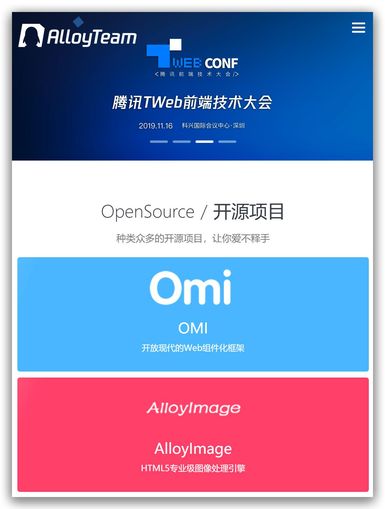

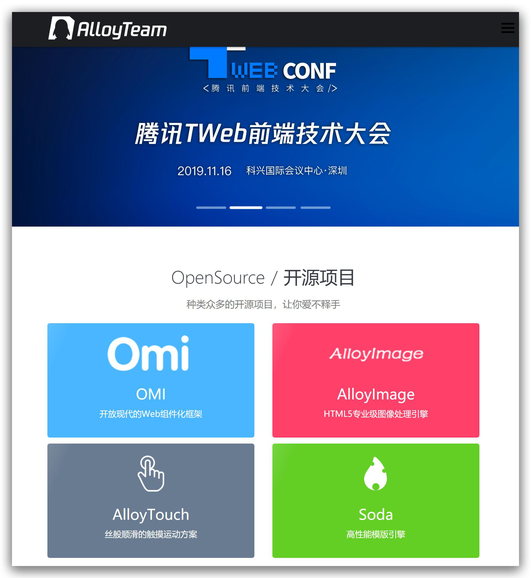

本课两条实现路径是媒体查询和Bootstrap。媒体查询直接写条件与CSS；Bootstrap把常用条件和布局规则封装成类名，仍然需要按它要求的结构使用。

所有课堂页面均保留移动端视口设置，使手机上的布局视口与设备宽度对应：

```html
<meta name="viewport" content="width=device-width, initial-scale=1.0">
```

本课宽度条件判断的是**视口宽度（CSS像素）**，不等同于设备硬件的物理像素数量。


### 1.2 基本写法：max-width 与 min-width

媒体查询的形式是：条件满足时，内部CSS参加样式计算。

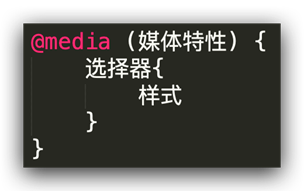

```css
@media (width: 320px) {
  html {
    background-color: green;
  }
}
```

这是PPT的等值示例，只有视口恰为320px宽时匹配。更常用的是范围条件：

| 条件 | 含义 | 边界是否包含 |
| --- | --- | --- |
| `(max-width: 768px)` | 视口宽度小于或等于768px | 包含768px |
| `(min-width: 1200px)` | 视口宽度大于或等于1200px | 包含1200px |

目标文件：`code/01-媒体查询.html`。完整课堂源码如下。

```html
<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta http-equiv="X-UA-Compatible" content="IE=edge" />
    <meta name="viewport" content="width=device-width, initial-scale=1.0" />
    <title>媒体查询</title>
    <style>
      /* 屏幕宽度小于等于768，网页背景色是粉色 → max-width */
      @media (max-width: 768px) {
        body {
          background-color: pink;
        }
      }


      /* 屏幕宽度大于等于1200，网页背景色是绿色 → min-width */
      @media (min-width:1200px) {
        body {
          background-color: green;
        }
      }

    </style>
  </head>
  <body>

  </body>
</html>
```

这个文件实际改变`body`背景：宽度不超过768px时粉色，达到1200px时绿色。768px与1200px之间的区间没有设置背景色，不能把它解释成会保持上一个视口状态的颜色；浏览器会按当前匹配条件重新计算。

打开HTML，用设备模拟或调整浏览器宽度，检查768px、769px、1199px、1200px。前后两个条件互不重叠，能直接看到边界是否包含。


### 1.3 书写顺序与重叠条件

原课需求：默认灰色；宽度达到768px变粉色，达到992px变绿色，达到1200px变天蓝色。

目标文件：`code/02-媒体查询-书写顺序.html`。

```html
<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta http-equiv="X-UA-Compatible" content="IE=edge" />
    <meta name="viewport" content="width=device-width, initial-scale=1.0" />
    <title>Document</title>
    <style>
      /* 网页默认背景色是灰色 */
      body {
        background-color: #ccc;
      }
      /* 屏幕宽度 大于等于 768px，网页背景色是粉色 min */
      @media (min-width: 768px) {
        body {
          background-color: pink;
        }
      }
      /* 屏幕宽度 大于等于 992px，网页背景色是绿色 min */
      @media (min-width:992px) {
        body {
          background-color: green;
        }
      }

      /* 屏幕宽度 大于等于 1200px，网页背景色是 skyblue  min */
      @media (min-width: 1200px) {
        body {
          background-color: skyblue;
        }
      }
    </style>
  </head>
  <body></body>
</html>
```

`min-width`查询从小到大书写。1200px宽时，三个查询都成立；它们都使用`body`选择器设置背景，在优先级相同的情况下，后面的天蓝色覆盖前面的绿色和粉色。

| 当前视口宽度 | 最终背景 |
| --- | --- |
| 小于768px | 灰色`#ccc` |
| 768px到小于992px | 粉色 |
| 992px到小于1200px | 绿色 |
| 大于或等于1200px | 天蓝色 |

> 原课顺序：`min-width`从小到大，`max-width`从大到小。这样在多个条件同时匹配时，后写的规则可以覆盖到更具体的区间。

补充：媒体查询不是`if / else if`，不会只选一个分支；“越窄的区间自动优先”也不是CSS规则。最终还取决于选择器优先级、`!important`和源码顺序。本例选择器和声明级别相同，顺序才直接决定颜色。

练习时特别检查992px和1200px，而不仅是远离断点的设备宽度。


### 1.4 案例：小视口隐藏左侧区域

需求：视口宽度小于或等于768px时隐藏左侧区域，使主体获得空间。

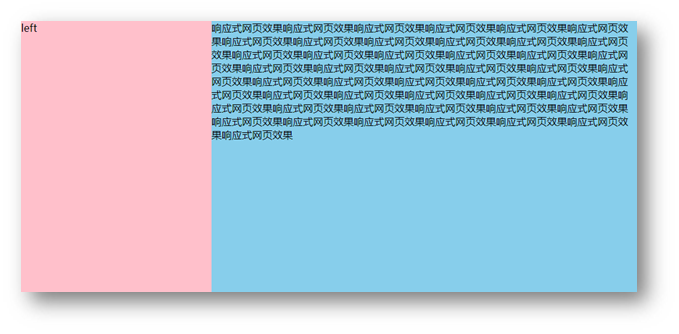

目标文件：`code/03-媒体查询-隐藏.html`。完整源码如下。

```html
<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta http-equiv="X-UA-Compatible" content="IE=edge" />
    <meta name="viewport" content="width=device-width, initial-scale=1.0" />
    <title>隐藏效果</title>
    <style>
      * {
        margin: 0;
        padding: 0;
      }

      .box {
        display: flex;
      }

      .left {
        width: 300px;
        height: 500px;
        background-color: pink;
      }

      .main {
        flex: 1;
        height: 500px;
        background-color: skyblue;
      }

      @media (max-width: 768px) {
        .left {
          display: none;
        }
      }
    </style>
  </head>
  <body>
    <div class="box">
      <div class="left">left</div>
      <div class="main">
        响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果响应式网页效果
      </div>
    </div>
  </body>
</html>
```

`.box`用Flex横向排列两个区域。左侧设计宽300px、高500px；主体`flex: 1`分配剩余空间，背景天蓝色。查询匹配时给`.left`设置`display: none`，它不再占据布局位置，主体扩展到容器可用宽度。

这里使用`display: none`，所以隐藏后不保留一个300px空位。宽度回到768px以上时，查询不再生效，左侧按默认规则重新显示。

验证：先在较宽视口观察左右两区，再切到768px，粉色区域应消失；切到769px，它应恢复。原文把HTML代码块标成CSS，笔记按实际内容标为HTML。


### 1.5 完整写法、媒体类型与媒体特性

原课这一部分用于了解完整结构：

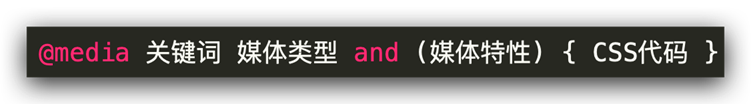

```css
@media only screen and (min-width: 768px) {
  body {
    background-color: pink;
  }
}
```

媒体类型区分应用场景，媒体特性描述该场景下的具体条件。

| 媒体类型 | 原课说明 |
| --- | --- |
| `screen` | 屏幕设备，手机、平板和电脑都属于此类 |
| `print` | 打印及打印预览 |
| `speech` | 原课列出的语音输出类型 |
| `all` | 不限定媒体类型；默认类型 |

> 补充：`speech`不能理解为开启任意屏幕阅读器就会自动切换的网页模式。这里保留课件的类型介绍，实际页面主要使用屏幕及视口宽度条件。

| 关键词 | 当前写法中的作用 |
| --- | --- |
| `and` | 连接媒体类型与特性，要求这些条件同时满足 |
| `only` | 兼容旧式只识别媒体类型的浏览器；现代浏览器中不改变查询的真假结果 |
| `not` | 在原课这种传统写法中，对整条媒体查询取反 |

例如`screen and (min-width: 768px) and (max-width: 991px)`同时限制屏幕类型与宽度上下界。

| 媒体特性 | 检查内容 |
| --- | --- |
| `width`、`height` | 视口的宽、高等值条件 |
| `max-width`、`max-height` | 视口最大宽、高，包含边界 |
| `min-width`、`min-height` | 视口最小宽、高，包含边界 |
| `orientation: portrait` | 视口竖向，高大于或等于宽 |
| `orientation: landscape` | 视口横向，宽大于高 |

> 补充：原Markdown把竖屏拼成了`protrait`，PPT写的是正确的`portrait`。方向条件依据视口宽高关系，不直接读取设备是否旋转。


### 1.6 用 link 的 media 属性应用外部 CSS

条件也可以写在`link`的`media`属性上，把不同条件下的样式放到独立文件。

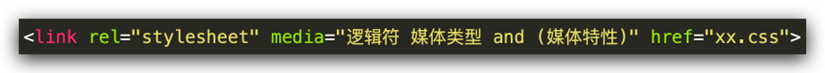

目标文件：`code/04-媒体查询-link.html`。

```html
<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta http-equiv="X-UA-Compatible" content="IE=edge" />
    <meta name="viewport" content="width=device-width, initial-scale=1.0" />
    <title>媒体查询-link</title>
    <!-- 视口宽度 小于等于 768px， 网页背景色是粉色 -->
    <link rel="stylesheet" media="(max-width: 768px)" href="./pink.css">
    <!-- 视口宽度 大于等于 1200px，网页背景色是绿色 -->
    <link rel="stylesheet" media="(min-width: 1200px)" href="./green.css">
  </head>
  <body>

  </body>
</html>
```

同目录`pink.css`：

```css
body {
  background-color: pink;
}
```

同目录`green.css`：

```css
body {
  background-color: green;
}
```

`pink.css`在视口不超过768px时应用，`green.css`在视口达到1200px时应用，中间区间两者都不应用。切换宽度后条件会重新评估，无需更换HTML链接。

> 补充：`media`控制样式是否适用，不能据此断言不匹配的CSS绝不会被下载。检查效果时看实际应用的规则；文件路径则相对HTML所在目录。


## 2. Bootstrap


### 2.1 框架是什么，先体验响应式列数

Bootstrap是原课介绍的前端UI框架，提供已经编写好的CSS及常见交互组件。使用时引入对应文件，按文档给定的HTML结构和类名组合页面。

原课中文入口：[Bootstrap中文网](https://www.bootcss.com/)。选择Bootstrap 5的文档，与资料中的代码版本对应。

目标文件：`code/05-Bootstrap-体验.html`。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>体验Bootstrap</title>
  <link rel="stylesheet" href="./Bootstrap/css/bootstrap.min.css">
</head>
<body>
  <div class="container">
    <div class="row">
      <div class="col-lg-3 col-md-6 col-sm-12">1</div>
      <div class="col-lg-3 col-md-6 col-sm-12">1</div>
      <div class="col-lg-3 col-md-6 col-sm-12">1</div>
      <div class="col-lg-3 col-md-6 col-sm-12">1</div>
    </div>
  </div>
</body>
</html>
```

页面先引入`Bootstrap/css/bootstrap.min.css`，再使用`container → row → 列`结构。每项都带`col-lg-3 col-md-6 col-sm-12`：

- 视口达到992px时，每项占12份中的3份，一行四项。
- 768px到小于992px时，每项占6份，一行两项。
- 576px到小于768px时，每项占12份，一行一项。
- 小于576px时，本例列作为`.row`直接子级，框架的基础宽度仍为100%，也是一行一项。

这些响应规则已经写在框架中，所以示例没有再自己写`@media`。


### 2.2 下载生产文件，并引入响应式版心

原课下载顺序：Bootstrap V5中文文档 → 进入中文文档 → 下载 → 下载Bootstrap生产文件。

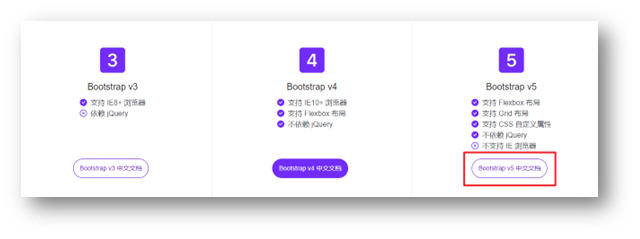

资料`素材/`已经提供`bootstrap-5.3.0-alpha1-dist.zip`，课堂`code/Bootstrap/`中也有可直接引用的CSS和JS。生产文件是已编译的文件，开发练习时可以直接使用，不必先处理框架源码。

目标文件：`code/06-Bootstrap-使用.html`。先链接CSS，再调用`.container`。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>使用方法</title>
  <link rel="stylesheet" href="./Bootstrap/css/bootstrap.min.css">
  <style>
    div {
      height: 50px;
      background-color: pink;
    }
  </style>
</head>
<body>
  <div class="container">1</div>
</body>
</html>
```

`.container`是响应式版心：默认宽100%、左右有内边距、左右外边距自动；随着视口到达不同断点，框架设置不同的最大宽度，使内容居中。

本例自写的`div`样式只是让版心高50px、背景粉色，方便观察；版心宽度与居中效果由Bootstrap提供。基础版心和栅格、按钮、表格的展示只需CSS，折叠与轮播等交互再引入JS。


### 2.3 栅格系统：12等份与6个响应区间

原课把一行可用宽度划分为12等份，每个列元素占指定份数。`row`提供Flex行与换行，列类控制宽度；一行四个等宽盒子，每个占`12 / 4 = 3`份。

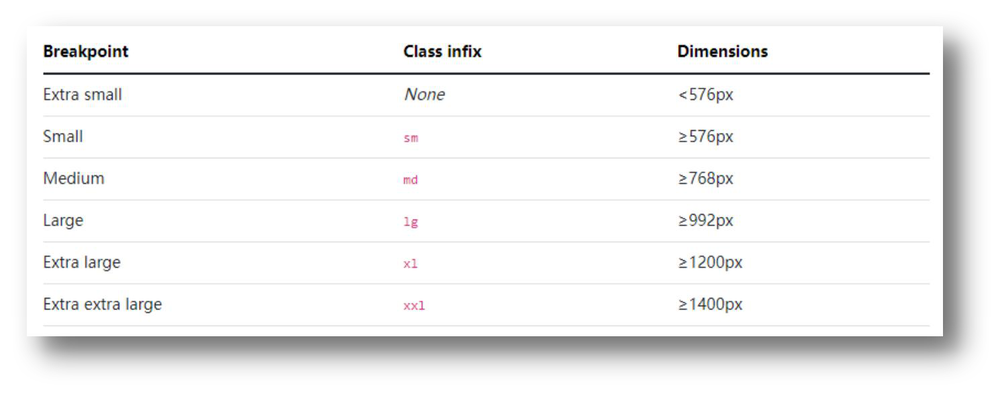

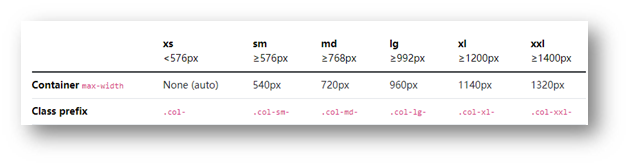

以下数值与资料包的Bootstrap CSS一致：

| 区间名称 | 当前视口区间 | 列类写法 | `.container`最大宽度 |
| --- | --- | --- | --- |
| xs | 小于576px | `col-*`，无`xs`中缀 | 未设置断点最大宽度，基础宽100% |
| sm | 576px到小于768px | `col-sm-*` | 540px |
| md | 768px到小于992px | `col-md-*` | 720px |
| lg | 992px到小于1200px | `col-lg-*` | 960px |
| xl | 1200px到小于1400px | `col-xl-*` | 1140px |
| xxl | 大于或等于1400px | `col-xxl-*` | 1320px |

带断点的列类从该宽度起生效，也继续作用于更宽的视口，直到其他规则覆盖。例如`col-md-6`不只在md区间生效，若没有更大断点的列类，它在更宽视口中仍占50%。

> 补充：XMind中的`col-xs-*`、`lg ≥ 1200px`和1170/970/750px版心是旧版Bootstrap信息；本课PPT、HTML和实际库使用Bootstrap 5，采用上表。思维导图提到的“Less源码”也属于旧版残留，不作为本课下载步骤。


### 2.4 写一行四列、两列与一列的切换

目标文件：`code/07-Bootstrap-栅格系统.html`。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>栅格系统</title>
  <link rel="stylesheet" href="./Bootstrap/css/bootstrap.min.css">
</head>
<body>
  <!-- 
    视口宽度大于等于1200px，一行排4个盒子 → 3
    视口宽度大于等于768px，一行排2个盒子
    视口宽度大于等于576px，一行排1个盒子
   -->
   <!-- 版心 → row → 子级 -->
   <div class="container">
    <div class="row">
      <div class="col-xl-3 col-md-6 col-sm-12">1</div>
      <div class="col-xl-3 col-md-6 col-sm-12">2</div>
      <div class="col-xl-3 col-md-6 col-sm-12">3</div>
      <div class="col-xl-3 col-md-6 col-sm-12">4</div>
    </div>
   </div>
</body>
</html>
```

本例使用`col-xl-3 col-md-6 col-sm-12`，与体验文件的`col-lg-3`不同：

| 文件 | 开始排四列的宽度 | 两列区间 | 一列区间 |
| --- | --- | --- | --- |
| `05-Bootstrap-体验.html` | 992px | 768px到小于992px | 小于768px |
| `07-Bootstrap-栅格系统.html` | 1200px | 768px到小于1200px | 小于768px |

**列份数对应占一行的比例，不是列数量。** `col-xl-3`表示每项25%，不是一行三项；`col-md-6`表示每项50%，不是一行六项。

按`container → row → 列`嵌套，不要省略中间的`.row`。框架行和列的留白规则配合形成列间距，不需要额外给每列再补一整份宽度。

验证时在767/768px、1199/1200px两侧查看07文件，再用991/992px比较05文件。两份示例的四列断点不能混为一谈。


### 2.5 全局样式：按钮

按钮用基础类与功能、尺寸类组合：

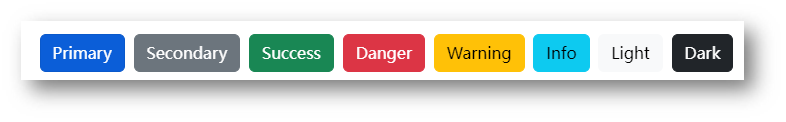

| 类名 | 作用 |
| --- | --- |
| `btn` | 按钮基础样式 |
| `btn-success` | 成功样式，示例为绿色 |
| `btn-warning` | 警告样式，示例为黄色 |
| `btn-sm` | 小尺寸 |
| `btn-lg` | 大尺寸 |

目标文件：`code/08-Bootstrap-按钮样式.html`。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>按钮样式</title>
  <link rel="stylesheet" href="./Bootstrap/css/bootstrap.min.css">
</head>
<body>
  <button class="btn btn-success btn-sm">按钮1</button>
  <button class="btn btn-warning btn-lg">按钮2</button>
</body>
</html>
```

第一个按钮组合`btn btn-success btn-sm`，第二个组合`btn btn-warning btn-lg`。引入CSS后应看到颜色、内边距和字号的差别；这里只验证样式，源码没有绑定按钮业务。


### 2.6 全局样式：表格

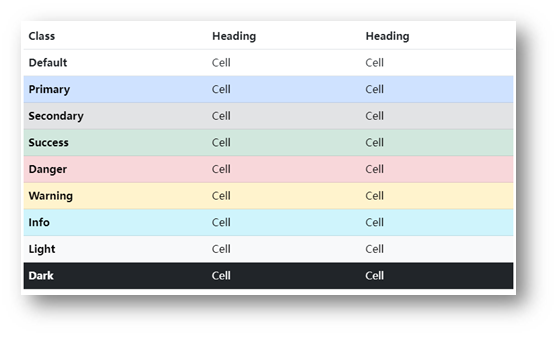

目标文件：`code/09-Bootstrap-表格样式.html`。

```html
<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta http-equiv="X-UA-Compatible" content="IE=edge" />
    <meta name="viewport" content="width=device-width, initial-scale=1.0" />
    <title>表格样式</title>
    <link rel="stylesheet" href="./Bootstrap/css/bootstrap.min.css">
  </head>
  <body>
    <table class="table table-striped table-hover">
      <tr class="table-success">
        <th>姓名</th>
        <th>年龄</th>
        <th>性别</th>
      </tr>
      <tr>
        <td>张三</td>
        <td>18</td>
        <td>男</td>
      </tr>
      <tr>
        <td>李四</td>
        <td>20</td>
        <td>女</td>
      </tr>
      <tr>
        <td>王五</td>
        <td>18</td>
        <td>男</td>
      </tr>
      <tr>
        <td>赵六</td>
        <td>20</td>
        <td>女</td>
      </tr>
    </table>
  </body>
</html>
```

`.table`提供基础表格样式，`.table-striped`增加隔行效果，`.table-hover`增加鼠标悬停效果。示例把`.table-success`放在第一行`tr`上，为该行设置成功配色；没有把整个表都设为绿色。

保留原表格数据，打开后检查行间颜色与鼠标移入普通数据行时的变化。这些效果由CSS提供。


### 2.7 组件：引入 JS，并保持结构关联

原课使用组件的顺序：引入框架CSS → 引入JS → 从对应版本文档复制结构并修改内容。

目标文件：`code/10-Bootstrap-组件.html`。它包含折叠导航和四张图轮播，完整源码如下。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>组件</title>
  <link rel="stylesheet" href="./Bootstrap/css/bootstrap.min.css">
  <style>
    .bg-body-tertiary {
      background-color: pink !important;
    }
  </style>
</head>
<body>
  <!-- 导航 -->
  <nav class="navbar navbar-expand-lg bg-body-tertiary">
    <div class="container-fluid">
      <a class="navbar-brand" href="#">Navbar</a>
      <button class="navbar-toggler" type="button" data-bs-toggle="collapse" data-bs-target="#navbarNav" aria-controls="navbarNav" aria-expanded="false" aria-label="Toggle navigation">
        <span class="navbar-toggler-icon"></span>
      </button>
      <div class="collapse navbar-collapse" id="navbarNav">
        <ul class="navbar-nav">
          <li class="nav-item">
            <a class="nav-link active" aria-current="page" href="#">首页</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="#">课程</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="#">课程资料</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="#">视频</a>
          </li>
        </ul>
      </div>
    </div>
  </nav>

  <!-- 轮播图 -->
  <div id="carouselExampleIndicators" class="carousel slide">
    <div class="carousel-indicators">
      <button type="button" data-bs-target="#carouselExampleIndicators" data-bs-slide-to="0" class="active" aria-current="true" aria-label="Slide 1"></button>
      <button type="button" data-bs-target="#carouselExampleIndicators" data-bs-slide-to="1" aria-label="Slide 2"></button>
      <button type="button" data-bs-target="#carouselExampleIndicators" data-bs-slide-to="2" aria-label="Slide 3"></button>
      <button type="button" data-bs-target="#carouselExampleIndicators" data-bs-slide-to="3" aria-label="Slide 4"></button>
    </div>
    <div class="carousel-inner">
      <div class="carousel-item active">
        <img src="./images/banner_1.jpg" class="d-block w-100" alt="...">
      </div>
      <div class="carousel-item">
        <img src="./images/banner_2.jpg" class="d-block w-100" alt="...">
      </div>
      <div class="carousel-item">
        <img src="./images/banner_3.jpg" class="d-block w-100" alt="...">
      </div>
      <div class="carousel-item">
        <img src="./images/banner_4.jpg" class="d-block w-100" alt="...">
      </div>
    </div>
    <button class="carousel-control-prev" type="button" data-bs-target="#carouselExampleIndicators" data-bs-slide="prev">
      <span class="carousel-control-prev-icon" aria-hidden="true"></span>
      <span class="visually-hidden">Previous</span>
    </button>
    <button class="carousel-control-next" type="button" data-bs-target="#carouselExampleIndicators" data-bs-slide="next">
      <span class="carousel-control-next-icon" aria-hidden="true"></span>
      <span class="visually-hidden">Next</span>
    </button>
  </div>

  <script src="./Bootstrap/js/bootstrap.min.js"></script>
</body>
</html>
```

导航的关键对应关系：

| 位置 | 当前示例中的作用 |
| --- | --- |
| `navbar-expand-lg` | 达到992px展开导航；更窄时使用折叠按钮 |
| `data-bs-toggle="collapse"` | 按钮调用折叠组件 |
| `data-bs-target="#navbarNav"` | 指向折叠容器的ID |
| `id="navbarNav"` | 被按钮控制的导航容器 |
| `aria-controls`、`aria-expanded`、`aria-label` | 描述按钮控制对象与状态，保留原组件提供的信息 |

自写的`.bg-body-tertiary`用粉色`!important`覆盖框架背景，因为框架同名背景声明也带`!important`；同级声明由后写的样式覆盖。不要把“业务CSS写后面”理解为永远能覆盖框架任意规则。

轮播的外层ID是`carouselExampleIndicators`；指示器与前后按钮的`data-bs-target`必须指向它。`data-bs-slide-to`从0开始，四张图对应0～3；`data-bs-slide="prev" / "next"`控制前后切换。第一张及其指示器带`active`。

`d-block w-100`让这里的`img`显示为块并宽度100%。这份体验文件直接使用图片；综合案例会改用固定高度的背景图。

引入脚本后，在窄视口点击导航按钮，检查展开与收起；点击轮播前后按钮及指示器，检查四张图片。原体验文件没有`data-bs-ride="carousel"`或额外初始化代码，不能把页面加载后的自动播放写成已配置行为。


### 2.8 字体图标：单独下载并保留 fonts 路径

Bootstrap Icons是独立图标库，不是引入`bootstrap.min.css`后自动拥有的字体图标。

原课步骤：导航/Extend → 图标库 → 安装 → 下载`bootstrap-icons-1.X.X.zip`；将字体目录和`bootstrap-icons.css`放入项目，链接CSS，调用图标类。

资料已提供`素材/bootstrap-icons-1.10.4.zip`。原笔记的示例下载链接指向1.10.3，但配套实际包为1.10.4，练习按已提供的文件使用。

目标文件：`code/11-Bootstrap-字体图标.html`。

```html
<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta http-equiv="X-UA-Compatible" content="IE=edge" />
    <meta name="viewport" content="width=device-width, initial-scale=1.0" />
    <title>字体图标</title>
    <link rel="stylesheet" href="./Bootstrap/font/bootstrap-icons.css">
    <style>
      .bi-android2 {
        font-size: 100px;
        color: green;
      }
    </style>
  </head>
  <body>
    <span class="bi-android2"></span>
  </body>
</html>
```

实际路径关系：

```text
Bootstrap/
  font/
    bootstrap-icons.css
    fonts/
      bootstrap-icons.woff2
      bootstrap-icons.woff
```

CSS中的字体地址相对CSS自身所在位置。原图标CSS中与当前示例相关的完整规则如下：

```css
@font-face {
  font-display: block;
  font-family: "bootstrap-icons";
  src: url("./fonts/bootstrap-icons.woff2?1fa40e8900654d2863d011707b9fb6f2") format("woff2"),
url("./fonts/bootstrap-icons.woff?1fa40e8900654d2863d011707b9fb6f2") format("woff");
}

.bi::before,
[class^="bi-"]::before,
[class*=" bi-"]::before {
  display: inline-block;
  font-family: bootstrap-icons !important;
  font-style: normal;
  font-weight: normal !important;
  font-variant: normal;
  text-transform: none;
  line-height: 1;
  vertical-align: -.125em;
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}
```

```css
.bi-android2::before { content: "\f7d1"; }
```

HTML用`span.bi-android2`，字号100px、颜色绿色；原笔记用`i`也是同样调用类名的方式。字体由伪元素显示，元素内部不需要手填字符。

若图标显示方块，检查图标CSS、类名和两个字体文件路径。保留整个字体包即可，不必把库的全部图标映射复制进业务样式。


## 3. 综合案例：AlloyTeam（腾讯全端）

原课顺序：准备 → 头部导航 → 轮播图片 → 轮播响应式 → 开源项目响应式 → 项目内容布局。

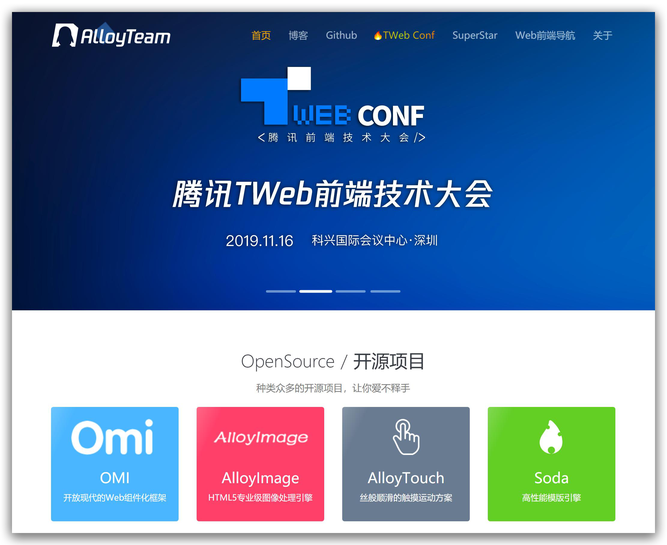

参考图展示成品区域关系。课堂`code/alloyTeam/`在本节结束时，项目内容仍为四个彩色占位块；完整内容及后续版块在同一天配套作业中提供，见第4节。


### 3.1 准备工作：目录与样式加载顺序

项目目录：`code/alloyTeam/`。素材目录`素材/alloyTeam/`已给图片、框架、字体图标和站点图标；从素材练习时再创建`index.html`、`less/index.less`和编译输出的`css/index.css`。

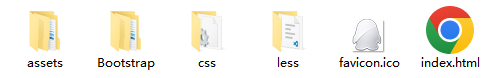

| 路径 | 用途 |
| --- | --- |
| `assets/images/` | 标识和项目、分类图片 |
| `assets/uploads/` | 四张banner及作品、人物图片 |
| `Bootstrap/css/bootstrap.min.css` | 框架样式 |
| `Bootstrap/font/bootstrap-icons.css` | 图标字体入口 |
| `Bootstrap/js/bootstrap.min.js` | 折叠导航及轮播交互 |
| `less/index.less` | 当前页面的定制样式 |
| `css/index.css` | 编译后供浏览器读取的样式 |
| `favicon.ico` | 浏览器标签的站点图标 |

框架CSS先引入，图标CSS次之，业务CSS最后。自写样式在相同声明级别和优先级下可以利用后写的顺序覆盖框架。

`less/index.less`开头：

```less
// out: ../css/
```

`// out: ../css/`是原课编译插件的输出注释约定。页面读取CSS，修改Less后需要通过已有编译流程更新CSS；这条注释不会让浏览器直接编译Less。


### 3.2 完整 HTML：导航、轮播与项目

目标文件：`code/alloyTeam/index.html`。完整课堂结构如下，后续各节按区域解释。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>腾讯全端</title>
  <link rel="shortcut icon" href="favicon.ico" type="image/x-icon">
  <!-- 层叠性：咱们的css 要 层叠 框架的 -->
  <link rel="stylesheet" href="./Bootstrap/css/bootstrap.min.css">
  <link rel="stylesheet" href="./Bootstrap/font/bootstrap-icons.css">
  <link rel="stylesheet" href="./css/index.css">
</head>
<body>
  <!-- 导航 -->
  <nav class="navbar navbar-expand-lg bg-body-tertiary fixed-top">
    <div class="container">
      <a class="navbar-brand" href="#"><img src="./assets/images/logo.png" alt=""></a>
      <button class="navbar-toggler" type="button" data-bs-toggle="collapse" data-bs-target="#navbarNav" aria-controls="navbarNav" aria-expanded="false" aria-label="Toggle navigation">
        <span class="navbar-toggler-icon"></span>
      </button>
      <div class="collapse navbar-collapse" id="navbarNav">
        <ul class="navbar-nav">
          <li class="nav-item">
            <a class="nav-link active" aria-current="page" href="#">首页</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="#">博客</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="#">Github</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="#">TWeb Conf</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="#">SuperStar</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="#">Web前端导航</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="#">关于</a>
          </li>
        </ul>
      </div>
    </div>
  </nav>

  <!-- 轮播图 -->
  <div id="carouselExampleIndicators" class="carousel slide">
    <div class="carousel-indicators">
      <button type="button" data-bs-target="#carouselExampleIndicators" data-bs-slide-to="0" class="active" aria-current="true" aria-label="Slide 1"></button>
      <button type="button" data-bs-target="#carouselExampleIndicators" data-bs-slide-to="1" aria-label="Slide 2"></button>
      <button type="button" data-bs-target="#carouselExampleIndicators" data-bs-slide-to="2" aria-label="Slide 3"></button>
      <button type="button" data-bs-target="#carouselExampleIndicators" data-bs-slide-to="3" aria-label="Slide 4"></button>
    </div>
    <div class="carousel-inner">
      <div class="carousel-item active">
        
      </div>
      <div class="carousel-item">
        
      </div>
      <div class="carousel-item">
        
      </div>
      <div class="carousel-item">
        
      </div>
    </div>
    <button class="carousel-control-prev" type="button" data-bs-target="#carouselExampleIndicators" data-bs-slide="prev">
      <span class="carousel-control-prev-icon" aria-hidden="true"></span>
      <span class="visually-hidden">Previous</span>
    </button>
    <button class="carousel-control-next" type="button" data-bs-target="#carouselExampleIndicators" data-bs-slide="next">
      <span class="carousel-control-next-icon" aria-hidden="true"></span>
      <span class="visually-hidden">Next</span>
    </button>
  </div>

  <!-- 开源项目 -->
  <div class="project container">
    <div class="title">
      <h2>OpenSource / 开源项目</h2>
      <p>种类众多的开源项目，让你爱不释手</p>
    </div>
    <div class="content">
      <div class="row">
        <div class="col-lg-3 col-md-6"><a href="#">1</a></div>
        <div class="col-lg-3 col-md-6"><a href="#">1</a></div>
        <div class="col-lg-3 col-md-6"><a href="#">1</a></div>
        <div class="col-lg-3 col-md-6"><a href="#">1</a></div>
      </div>
    </div>
  </div>
  

  <script src="./Bootstrap/js/bootstrap.min.js"></script>
</body>
</html>
```

它只有顶部导航、四张轮播背景和开源项目区域；没有作业中的作品、博客、明星或页脚。导航标识用`logo.png`，项目链接显示占位文字`1`。

`<script>`放在正文末尾引入Bootstrap；导航及项目的`href="#"`保留占位地址，框架交互与业务链接跳转是不同的事情。


### 3.3 头部导航：折叠、固定与定制背景

导航复用Bootstrap组件：`.navbar-expand-lg`在992px及以上展开，较窄时显示切换按钮；内部`.container`限制版心，`#navbarNav`对应折叠按钮。

`fixed-top`让导航固定在视口顶部，本例呈现在banner上方。它脱离文档流，页面顶部没有另加导航占位，因此banner从页面顶部开始。

目标规则：`less/index.less`中的导航部分。

```less
// 导航
.bg-body-tertiary {
  background-color: transparent !important;
  .navbar-collapse {
    flex-grow: 0;
  }
}
```

背景设为透明，使banner可在其后显示；`!important`用于覆盖框架背景工具类的同级重要声明。`.navbar-collapse`的`flex-grow: 0`取消它占满剩余空间的扩展，使标识与导航内容结合框架的左右布局排开。

检查窄视口点击是否控制到当前导航，大视口是否展开并显示右侧链接。课堂没有配置滚动后变深色或收缩高度；这些行为来自配套作业。


### 3.4 轮播图片：空元素由背景填充

HTML里四个`.carousel-item`没有`img`，图片由Less的`nth-child(1)`到`nth-child(4)`设置。指示器和前后按钮仍指向`#carouselExampleIndicators`，第一项带`active`。

下面完整保留最终轮播规则，其中高度的媒体查询是下一节要讲的响应式步骤。

```less
// 轮播图: 小于768图片高度250 max；大于等于768图片高度400 min；大于等于992图片高度500
.carousel {
  // 响应式 → 媒体查询
  @media (max-width: 768px) {
    .carousel-item {
      height: 250px;
    }
  }

  @media (min-width: 768px) {
    .carousel-item {
      height: 400px;
    }
  }
  @media (min-width: 992px) {
    .carousel-item {
      height: 500px;
    }
  }


  .carousel-item {
    // height: 500px;
    background-size: cover;
    background-position: center 0;
  }
  .carousel-item:nth-child(1) {
    background-image: url(../assets/uploads/banner_1.jpg);
  }
  .carousel-item:nth-child(2) {
    background-image: url(../assets/uploads/banner_2.jpg);
  }
  .carousel-item:nth-child(3) {
    background-image: url(../assets/uploads/banner_3.jpg);
  }
  .carousel-item:nth-child(4) {
    background-image: url(../assets/uploads/banner_4.jpg);
  }
}
```

`background-size: cover`让背景按自身比例缩放并覆盖盒子，比例不同的部分会裁切；`background-position: center 0`使水平方向居中、垂直方向贴顶。

四张图片按DOM顺序对应`banner_1.jpg`～`banner_4.jpg`。路径相对编译后的`css/index.css`所在目录，因此使用`../assets/uploads/`。

原课先用500px固定高度查看图片，最终把无条件的`height: 500px`注释掉，交给媒体查询设置。不要重新启用这条后写的无条件高度，否则它会覆盖前面查询中的同级高度声明。


### 3.5 轮播响应式：精确检查768px的重叠

继续看上一节轮播规则，Less中的嵌套查询编译成外层`@media`，内部选择器为`.carousel .carousel-item`。

| 当前视口宽度 | 匹配查询 | 最终高度 |
| --- | --- | --- |
| 小于768px | `max-width: 768px` | 250px |
| 恰为768px | `max-width: 768px`和`min-width: 768px` | 400px，后写规则覆盖 |
| 大于768px到小于992px | `min-width: 768px` | 400px |
| 大于或等于992px | `min-width: 768px`及`min-width: 992px` | 500px |

> 补充：原注释说“小于768”，实际第一条`max-width`包含768px。恰在768px时两条都成立，最终400px；恰在992px时最终500px。原代码保留这组重叠条件。

验证时用767px、768px、991px、992px观察banner高度，然后点击指示器确认所有背景都能切换。不同高度下裁切范围变化是`cover`的正常结果。


### 3.6 开源项目响应式：先搭列结构

项目区域使用`.project.container`，标题包含`h2`和`p`，内容保持`row → 列 → a`关系。每列类名是`col-lg-3 col-md-6`，与07示例的`col-xl-3`不同。

| 当前视口宽度 | 每项宽度 | 每行项目数 |
| --- | --- | --- |
| 小于768px | 行直接子级基础宽100% | 1 |
| 768px到小于992px | 6/12，即50% | 2 |
| 大于或等于992px | 3/12，即25% | 4 |

`.project`上间距60px，文字居中。原笔记先用数字建立四个列，再给各列增加链接并填颜色；完整最终规则放在下一节。

> 补充：原Less注释写“视口宽度大于992/768”，列类实际使用大于或等于的断点，992px已经是四列，768px已经是两列。


### 3.7 开源项目内容布局：彩色占位卡片

目标规则：`less/index.less`的项目部分。

```less
// 开源项目
// 视口宽度大于992；一行排4个盒子  col-lg-3
// 视口宽度大于768；一行排2个盒子  col-md-6
.project {
  margin-top: 60px;
  text-align: center;
  .row {
    div {
      margin-bottom: 10px;
      height: 200px;
      // background-color: pink;
      a {
        // 块级的宽度和父级一样大
        display: block;
        height: 200px;
        background-color: green;
        border-radius: 4px;
      }

      &:nth-child(1) a {
        background-color: #70c3ff;
      }
      &:nth-child(2) a {
        background-color: #fd6a7f;
      }
      &:nth-child(3) a {
        background-color: #7f8ea0;
      }
      &:nth-child(4) a {
        background-color: #89d04f;
      }
    }
  }
}
```

列元素下间距10px、高200px。链接设为块后填满列的内容宽度，同样高200px，圆角4px。这里仍使用框架列内边距留出横向空隙。

`&:nth-child(1) a`等嵌套写法选择当前列在这一行结构中的序号，分别给链接设置蓝、粉、灰、绿四种背景。原基础`background-color: green`被更具体的序号规则覆盖；粉色调试背景处于注释状态。

当前HTML四个链接都写`1`，没有项目图标、名称、介绍或悬停动画。对照成品图时，以课堂实际代码状态为准。


### 3.8 编译结果与课堂案例检查

原`code/alloyTeam/css/index.css`完整内容：

```css
.bg-body-tertiary {
  background-color: transparent !important;
}
.bg-body-tertiary .navbar-collapse {
  flex-grow: 0;
}
@media (max-width: 768px) {
  .carousel .carousel-item {
    height: 250px;
  }
}
@media (min-width: 768px) {
  .carousel .carousel-item {
    height: 400px;
  }
}
@media (min-width: 992px) {
  .carousel .carousel-item {
    height: 500px;
  }
}
.carousel .carousel-item {
  background-size: cover;
  background-position: center 0;
}
.carousel .carousel-item:nth-child(1) {
  background-image: url(../assets/uploads/banner_1.jpg);
}
.carousel .carousel-item:nth-child(2) {
  background-image: url(../assets/uploads/banner_2.jpg);
}
.carousel .carousel-item:nth-child(3) {
  background-image: url(../assets/uploads/banner_3.jpg);
}
.carousel .carousel-item:nth-child(4) {
  background-image: url(../assets/uploads/banner_4.jpg);
}
.project {
  margin-top: 60px;
  text-align: center;
}
.project .row div {
  margin-bottom: 10px;
  height: 200px;
}
.project .row div a {
  display: block;
  height: 200px;
  background-color: green;
  border-radius: 4px;
}
.project .row div:nth-child(1) a {
  background-color: #70c3ff;
}
.project .row div:nth-child(2) a {
  background-color: #fd6a7f;
}
.project .row div:nth-child(3) a {
  background-color: #7f8ea0;
}
.project .row div:nth-child(4) a {
  background-color: #89d04f;
}
```

保存Less并更新这份CSS后，打开项目`index.html`，检查：

1. 框架、图标和业务CSS按原顺序链接，图片及JS路径正确。
2. 767px下轮播高250px、项目一列；768px下高400px、项目两列；992px下高500px、项目四列。
3. 窄视口切换导航、大视口展开导航；轮播按钮和指示器控制当前四张背景。
4. 项目卡片按蓝、粉、灰、绿顺序排列，保留200px高度和列间留白。
5. 滚动时顶部导航固定；课堂没有自动轮播初始化和自写滚动监听，导航及项目链接仍为占位地址。


## 4. 配套作业：AlloyTeam完整页面

`作业/AlloyTeam/`在同一资料包中提供完整页面，继续使用Bootstrap 5，并加入文案、作品、博客、明星、页脚、悬停效果和滚动导航。以下按作业实际结构阅读，不把新增版块当成课堂已完成内容。


### 4.1 基础样式与完整 HTML

作业HTML链接同目录`css/bootstrap.min.css`和`css/index.css`，正文末尾先引入`js/bootstrap.min.js`，再引入`js/index.js`。这里未链接Bootstrap Icons，标识与卡片图片使用素材文件。

`less/base.less`由业务Less导入，完整内容如下：

```less
// out: false
*,
::after,
::before {
  box-sizing: border-box;
}

body {
  font-family:
    -apple-system,
    BlinkMacSystemFont,
    PingFangSC-Regular,
    "PingFang SC",
    "Microsoft YaHei",
    "Helvetica Neue",
    Helvetica,
    Arial,
    sans-serif;
  font-size: 14px;
  -webkit-font-smoothing: antialiased;
  color: #494d55;
}

img {
  vertical-align: bottom;
}

ul {
  list-style-type: none;
}

a {
  color: #494d55;
  text-decoration: none;
  -webkit-tap-highlight-color: rgb(0 0 0 / 0%);
}
```

基础样式设置盒模型、系统字体、14px基础字号、文本色`#494d55`、图片底部对齐及链接样式。页面其他默认初始化由Bootstrap的样式参与提供。

`less/index.less`开头：

```less
// out: "../css/"
@import './base.less';
```

完整`作业/AlloyTeam/index.html`：

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width,initial-scale=1">
  <title>AlloyTeam|腾讯全端 AlloyTeam 团队</title>
  <meta name="keywords" content="AlloyTeam 前端 腾讯 腾讯前端">
  <meta name="description" content="腾讯全端AlloyTeam团队">
  <link rel="shortcut icon" href="./favicon.ico">
  <link rel="stylesheet" href="./css/bootstrap.min.css">
  <link rel="stylesheet" href="./css/index.css">
</head>
<body>
  <!-- 主导航 -->
  <nav class="navbar navbar-dark navbar-expand-lg fixed-top">
    <div class="container">
      <a class="navbar-brand" href="#">
        <h1 class="logo">AlloyTeam</h1>
      </a>
      <button class="navbar-toggler" type="button" data-bs-toggle="collapse" data-bs-target="#navbar-collapse" aria-controls="navbarSupportedContent" aria-expanded="false" aria-label="Toggle navigation">
        <span class="navbar-toggler-icon"></span>
      </button>
      <div class="collapse navbar-collapse" id="navbar-collapse">
        <ul class="navbar-nav">
          <li class="nav-item">
            <a class="nav-link active" href="javascript:;">首页</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="javascript:;">博客</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="javascript:;">Github</a>
          </li>
          <li class="nav-item">
            <a class="nav-link hot" href="javascript:;">TWeb Conf</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="javascript:;">SuperStar</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="javascript:;">Web前端导航</a>
          </li>
          <li class="nav-item">
            <a class="nav-link" href="#">关于</a>
          </li>
        </ul>
      </div>
    </div>  
  </nav>

  <!-- 轮播图 -->
  <div class="carousel slide" id="alloyCarousel" data-bs-ride="carousel" data-bs-interval="5000">
    <!-- Indicators -->
    <ol class="carousel-indicators">
      <li data-bs-target="#alloyCarousel" data-bs-slide-to="0" class="active"></li>
      <li data-bs-target="#alloyCarousel" data-bs-slide-to="1"></li>
      <li data-bs-target="#alloyCarousel" data-bs-slide-to="2"></li>
      <li data-bs-target="#alloyCarousel" data-bs-slide-to="3"></li>
    </ol>
    <!-- Slides -->
    <div class="carousel-inner">
      <div class="carousel-item active">
        <a href="#">
          <div class="container hire-info">
            <p class="hire-name">腾讯AlloyTeam招聘Web+工程师<br>2023</p>
            <p class="hire-title">征不平凡的你</p>
          </div>
        </a>
      </div>
      <div class="carousel-item"></div>
      <div class="carousel-item">
        <a href="#">
          <div class="container item-info">
            <p class="title-name">Alloy前端周刊</p>
            <p class="title-desc">为您带来精彩有料的前端好文</p>
          </div>
        </a>
      </div>
      <div class="carousel-item">
        <a href="#">
          <div class="container item-info special">
            <p class="title-name">Omi</p>
            <p class="title-desc">开放现代的web组件化框架</p>
          </div>
        </a>
      </div>
    </div>
  </div>

  <!-- 版块（开源项目） -->
  <div class="container section project">
    <!-- 标题 -->
    <h2 class="title">OpenSource / 开源项目<small>种类众多的开源项目，让你爱不释手</small></h2>
    <div class="row items">
      <div class="col-xs-12 col-sm-6 col-lg-3">
        <a href="#" class="omi">
          <img src="./assets/images/omi.png" alt="">
          <h3>OMI</h3>
          <p>开放现代的Web组件化框架</p>
        </a>
      </div>
      <div class="col-xs-12 col-sm-6 col-lg-3">
        <a href="#" class="alloyimage">
          <img src="./assets/images/alloyimage.png" alt="">
          <h3>OMI</h3>
          <p>开放现代的Web组件化框架</p>
        </a>
      </div>
      <div class="col-xs-12 col-sm-6 col-lg-3">
        <a href="#" class="alloytouch">
          <img src="./assets/images/alloytouch.png" alt="">
          <h3>OMI</h3>
          <p>开放现代的Web组件化框架</p>
        </a>
      </div>
      <div class="col-xs-12 col-sm-6 col-lg-3">
        <a href="#" class="soda">
          <img src="./assets/images/soda.png" alt="">
          <h3>OMI</h3>
          <p>开放现代的Web组件化框架</p>
        </a>
      </div>
    </div>
    <div class="more">
      <a href="#">更多开源 &gt;</a>
    </div>
  </div>

  <!-- 版块（作品） -->
  <section class="container section product">
    <!-- 标题 -->
    <h2 class="title">Product / 作品<small>新奇好玩的作品，让你欲罢不能</small></h2>
    <div class="row items">
      <div class="col-xs-12 col-sm-6 col-lg-3">
        <a href="javascript:;" class="item">
          <div class="img-wrap">
            <img src="./assets/uploads/codetank.jpg" alt="">
          </div>
          <p>Code Tank</p>
          <p>全世界首个Javascript程序员的在线编程对战游戏</p>
        </a>
      </div>
      <div class="col-xs-12 col-sm-6 col-lg-3">
        <a href="javascript:;" class="item">
          <div class="img-wrap">
            <img src="./assets/uploads/alloyphoto.jpg" alt="">
          </div>
          <p>AlloyPhoto</p>
          <p>专业在线图像处理App</p>
        </a>
      </div>
      <div class="col-xs-12 col-sm-6 col-lg-3">
        <a href="javascript:;" class="item">
          <div class="img-wrap">
            <img src="./assets/uploads/alloydesigner.png" alt="">
          </div>
          <p>AlloyDesigner</p>
          <p>新概念web开发工具</p>
        </a>
      </div>
      <div class="col-xs-12 col-sm-6 col-lg-3">
        <a href="javascript:;" class="item">
          <div class="img-wrap">
            <img src="./assets/uploads/alloystick.jpg" alt="">
          </div>
          <p>AlloyStick</p>
          <p>HTML5骨骼动画引擎</p>
        </a>
      </div>
    </div>
    <div class="more">
      <a href="#">更多作品 &gt;</a>
    </div>
  </section>

  <!-- 版块（博客） -->
  <section class="container section blog">
    <!-- 标题 -->
    <h2 class="title">Blog / 博客<small>最新技术发展，业界前沿博客</small></h2>
    <div class="row items">
      <div class="col-lg-6">
        <div class="inner">
          <h3>最新博客 <a href="#">...</a></h3>
          <ul class="list-unstyled">
            <li>
              <a href="#">
                <h5>Web Worker 文献综述</h5>
                <span>TAT. cntchen</span>
              </a>
            </li>
            <li>
              <a href="#">
                <h5>线程入门</h5>
                <span>TAT.vorshen</span>
              </a>
            </li>
            <li>
              <a href="#">
                <h5>给 JavaScript 插上多线程的翅膀 —— Web Worker 的 Promise 化实践</h5>
                <span>TAT.Duang</span>
              </a>
            </li>
            <li>
              <a href="#">
                <h5>脚本错误量极致优化-定位压缩且无 SourceMap 文件的脚本错误</h5>
                <span>TAT.joeyguo</span>
              </a>
            </li>
            <li>
              <a href="#">
                <h5>CSS Pixels</h5>
                <span>TAT.oliverzli</span>
              </a>
            </li>
          </ul>
        </div>
      </div>
      <div class="col-lg-6">
        <div class="inner">
          <h3>博客分类 <a href="#">...</a></h3>
          <div class="row">
            <div class="type col-md-6">
              <img src="./assets/images/javascript.png" alt="">
              <p class="name">Javascript</p>
              <p class="brief">没看过这些，怎么敢说懂js</p>
            </div>
            <div class="type col-md-6">
              <img src="./assets/images/css.png" alt="">
              <p class="name">CSS</p>
              <p class="brief">神奇的CSS在哪里？</p>
            </div>
            <div class="type col-md-6">
              <img src="./assets/images/nodejs.png" alt="">
              <p class="name">Nodejs</p>
              <p class="brief">亿万级数据服务的秘密</p>
            </div>
            <div class="type col-md-6">
              <img src="./assets/images/mobile.png" alt="">
              <p class="name">移动Web开发</p>
              <p class="brief">PC转向移动，这是个问题</p>
            </div>
            <div class="type col-md-6">
              <img src="./assets/images/users.png" alt="">
              <p class="name">用户体验设计</p>
              <p class="brief">震惊！原来应用还可以这样设计</p>
            </div>
            <div class="type col-md-6">
              <img src="./assets/images/performance.png" alt="">
              <p class="name">Web性能优化</p>
              <p class="brief">丝般柔顺体验背后的真相</p>
            </div>
          </div>
        </div>
      </div>
    </div>
  </section>

  <!-- 版块（超级明星） -->
  <section class="container section stars">
    <!-- 标题 -->
    <h2 class="title">SuperStar / 超级明星俱乐部<small>技术达人，最强大脑，前端先驱</small></h2>
    <div class="row items">
      <div class="col-lg-4">
        <div class="profile">
          <div class="img-wrap">
            <img src="./assets/uploads/jetyu.jpg" alt="">
          </div>
          <h5>JetYu 于涛</h5>
          <p>AlloyTeam 创始人</p>
        </div>
      </div>
      <div class="col-lg-4">
        <div class="profile">
          <div class="img-wrap">
            <img src="./assets/uploads/dntzhang.jpg" alt="">
          </div>
          <h5>DntZhang 张磊</h5>
          <p>知名博主，多个开源框架作者</p>
        </div>
      </div>
      <div class="col-lg-4">
        <div class="profile">
          <div class="img-wrap">
            <img src="./assets/uploads/dorsywang.jpg" alt="">
          </div>
          <h5>DorsyWang 王斌</h5>
          <p>数学达人，图像处理专家</p>
        </div>
      </div>
    </div>
    <div class="more">
      <a href="#">更多明星 ></a>
    </div>
  </section>

  <!-- 底部（版权、推广链接） -->
  <section class="footer">
    <div class="container">
      <div class="row">
        <div class="col-lg-5 webmeta">
          <img class="logo" src="./assets/images/logo.png" alt="">
          <h6 class="slogan">成为地球卓越的Web团队</h6>
          <p class="copyright">Copyright© 2023 AlloyTeam. All Rights Reserved.</p>
        </div>
        <div class="col-lg-2 d-none d-lg-block ">
          <h6 class="title">兄弟团队</h6>
          <a href="#">腾讯CDC</a>
          <a href="#">腾讯ISUX</a>
          <a href="#">腾讯TGideas</a>
          <a href="#">腾讯FERD</a>
          <a href="#">百度FEX</a>
          <a href="#">淘宝FED</a>
        </div>
        <div class="col-lg-2 d-none d-lg-block ">
          <h6 class="title">友情链接</h6>
          <a href="#">腾讯CDC</a>
          <a href="#">腾讯ISUX</a>
          <a href="#">腾讯TGideas</a>
          <a href="#">腾讯FERD</a>
          <a href="#">百度FEX</a>
          <a href="#">淘宝FED</a>
        </div>
        <div class="col-lg-3">
          <div class="row">
            <div class="col-md-6 col-xs-6 social">
              <img src="./assets/uploads/hm.jpg" alt="">
              <p>QQ群：162225981</p>
            </div>
            <div class="col-md-6 col-xs-6 social">
              <img src="./assets/uploads/hm.jpg" alt="">
              <p>微信公众号:AlloyTeam</p>
            </div>
          </div>
        </div>
      </div>
    </div>
  </section>
  <script src="./js/bootstrap.min.js"></script>
  <script src="./js/index.js"></script>
</body>
</html>
```

页面顺序为导航、轮播、开源项目、作品、博客、明星和页脚。作业四个开源项目使用不同图标与颜色，但名称和介绍仍都重复“OMI”“开放现代的Web组件化框架”，保留原文本。


### 4.2 导航样式及滚动状态

作业导航使用`.navbar-dark`、`.navbar-expand-lg`和`.fixed-top`，标识是`h1.logo`的SVG背景，文字字号设为0。完整导航样式包括下面的窄视口查询：

```less
/** 导航栏 */
.navbar {
  height: 70px;
  transition: .5s;

  &-brand {
    transition: .5s;

    .logo {
      width: 200px;
      height: 40px;
      background: url(../assets/images/logo.svg) no-repeat center / contain;
      font-size: 0;
      margin-bottom: 0;
    }
  }

  &-toggler {
    outline: none;
    border: none;
    box-shadow: none;

    &:focus {
      box-shadow: none;
    }
  }

  &-nav {
    width: 100%;
    display: flex;
    justify-content: flex-end;

    .nav-item {
      padding-top: 10px;
      margin-left: 20px;
      transition: .5s;

      .nav-link {
        font-size: 16px;

        &:hover, 
        &.active {
          color: #f2b535;
          background-color: transparent;
        }

        &.hot {
          background-image: linear-gradient(
            to right,
            #cddc39,
            #ff9800 25%,
            #cddc39 50%,
            #ff9800 75%,
            #cddc39
          );
          -webkit-text-fill-color: transparent;
          -webkit-background-clip: text;
          background-clip: text;
    
          &:before {
            content: '';
            display: inline-block;
            width: 13px;
            height: 15px;
            background-image: url(../assets/images/fire.png);
            background-size: 100% 100%;
            position: relative;
            top: 2px;
            right: 2px;
          }
        }
      }
    }
  }

  /** 卷曲动画 */
  &.scrolled {
    background-color: #26282c;
    height: 60px;
    padding-top: 0;
    padding-bottom: 0;
    
    .nav-item {
      padding-top: 0;
    }
  }
}

@media (max-width: 992px) {
  .navbar {
    &-collapse {
      border-top: none;
      box-shadow: none;
      width: 100%;
      left: 0;
      top: 60px;
      position: absolute;
      background: #26282c;
      z-index: 40;
      text-align: center;
    }

    .nav-item {
      margin-left: 0;
      padding-top: 0;
    }
  }
}
```

导航默认高70px；链接字号16px，悬停和`active`变为金色。`hot`链接用渐变裁到文字形成彩色文字，伪元素用`fire.png`显示火焰。

`.scrolled`状态把导航背景改为`#26282c`、高度改为60px，取消上下内边距和条目上内边距，结合0.5秒过渡改变状态。对应`js/index.js`全文：

```javascript

(function () {

  window.addEventListener('scroll', () => {
    const classList = document.querySelector('.navbar').classList
    if(document.documentElement.scrollTop >0) classList.add('scrolled')
    else classList.remove('scrolled')
  })

})()
```

脚本监听滚动，读取根元素`scrollTop`：大于0时给第一个`.navbar`添加`scrolled`，回到顶部时移除。源码仅在滚动事件中更新状态，没有单独的初始状态同步步骤。

窄视口导航内容设为绝对定位，顶部60px、背景深色、层级40，并去掉条目左间距。这里的查询是`max-width: 992px`，与框架`navbar-expand-lg`从992px起展开在边界上重叠，需单独观察992px。

> 补充：按钮实际目标是`#navbar-collapse`，与容器ID相同，所以折叠目标能对应；但原`aria-controls="navbarSupportedContent"`与该ID不一致，属于原HTML的描述差异。本笔记保留原代码。


### 4.3 轮播文字、自动播放与作业自己的断点

作业轮播ID为`alloyCarousel`，四个指示器均指向它；`data-bs-ride="carousel"`启用自动播放，`data-bs-interval="5000"`设置5000毫秒间隔。原结构没有课堂的前后箭头按钮。

完整轮播样式：

```less
/** 轮播图 */
.carousel {

  &-item {
    height: 500px;
    background-size: cover;
    background-position: center;

    /** 背景 */
    &:nth-child(1) {
      background-image: url("../assets//uploads/banner_1.jpg");
    }
    &:nth-child(2) {
      background-image: url("../assets//uploads/banner_2.jpg");
    }
    &:nth-child(3) {
      background-image: url("../assets//uploads/banner_3.jpg");
    }
    &:nth-child(4) {
      background-image: url("../assets//uploads/banner_4.jpg");
    }

    /** 内容 */
    .hire-info {
      position: relative;
      height: 100%;

      .hire-name {
        position: absolute;
        right: 60px;
        bottom: 160px;
        font-size: 40px;
        color: rgba(255,255,255,.9);
        text-align: center;
        letter-spacing: 3px;
        line-height: 60px;
        opacity: 0;
        transform: translateX(100%);
        transition: .5s;
      }

      .hire-title {
        position: absolute;
        bottom: 50px;
        font-size: 50px;
        color: hsla(0,0%,100%,.8);
        left: 50px;
        letter-spacing: 10px;
        opacity: 0;
        transform: translateX(-100%);
        transition: .5s;
      }
    }

    .item-info {
      color: #fff;
      text-align: center;
      width: 100%;
      height: 100%;
      padding-top: 180px;
      overflow: hidden;

      .title-name {
        font-size: 70px;
        padding-bottom: 20px;
        opacity: 0;
        transform: translateY(-200%);
        transition: .5s;
      }

      .title-desc {
        font-size: 40px;
        letter-spacing: 5px;
        opacity: 0;
        transform: translateY(200%);
        transition: .5s;
      }
    }

    /** 激活 */
    &.active {
      .hire-name, 
      .hire-title, 
      .title-name, 
      .title-desc {
        opacity: 1;
        transform: none;
      }
    }
  }
}

@media (max-width: 992px) {
  .carousel {
    &-item {
      height: 400px;
      .item-info {
        padding-top: 120px;
        .title-name {
          font-size: 56px;
        }
        .title-desc {
          font-size: 28px;
        }
      }
      .hire-info {
        .hire-name {
          bottom: 120px;
          font-size: 30px;
        }
        .hire-title {
          font-size: 36px;
          left: 0;
        }
      }
    }
  }
}
@media (max-width: 576px) {
  .carousel {
    &-item {
      height: 250px;
      .item-info {
        padding-top: 80px;
        .title-name {
          font-size: 35px;
        }
        .title-desc {
          font-size: 20px;
        }
      }
      .hire-info {
        .hire-name {
          bottom: 60px;
          right: 0;
          width: 100%;
          line-height: 36px;
          text-align: center;
        }
        .hire-title {
          display: none;
        }
      }
    }
  }
}
```

背景采用`cover`、水平和垂直居中。第一张包含招聘文字，第三张包含周刊文字，第四张包含Omi文字；第二张只有背景。文字初始透明并向外位移，活动项中的四种文字类设为`opacity: 1`和`transform: none`，配合0.5秒过渡显示。

| 当前视口宽度 | 作业轮播高度 | 与课堂的差异 |
| --- | --- | --- |
| 小于或等于576px | 250px | 第二条`max-width`覆盖第一条 |
| 大于576px到小于或等于992px | 400px | 作业992px仍为400px |
| 大于992px | 500px | 使用默认高度 |

作业还在992px以下减小标题字号与上内边距，在576px以下继续调整文字尺寸、居中招聘文字并隐藏`.hire-title`。这套断点不能用课堂767/768px的高度表代替。

原CSS背景路径中保留了`../assets//uploads/`的双斜线，资源仍在`assets/uploads/`。练习复制时按资料目录核对四张背景；自动轮播和文字过渡由Bootstrap活动项切换与业务CSS共同产生。


### 4.4 公共版块与开源项目卡片

公共`.section`设置40px下内边距、20px内容上间距，标题居中，副标题`small`独占一行并用灰色。更多按钮用Flex居中，圆角6px，并提供悬停颜色。

```less
// 版块（公共部分）
.section {
  padding-bottom: 40px;

  .items {
    margin-top: 20px;
  }

  .title {
    text-align: center;
    line-height: 2em;

    small {
      display: block;
      font-size: 16px;
      line-height: 2em;
      color: #919191;
      font-weight: 500;
    }
  }

  .more {
    display: flex;
    justify-content: center;
    padding: 10px 0;

    a {
      display: block;
      padding: 10px 16px;
      line-height: 1;
      font-size: 14px;
      border-radius: 6px;
      color: #616161;
      background-color: #e1e1e1;
      border: 1px solid #ccc;

      &:hover {
        color: #333;
        background-color: #e6e6e6;
        border-color: #adadad;
      }
    }
  }
}
```

开源项目完整样式：

```less
// 版块（开源项目）
.project {
  margin-top: 40px;

  .items {

    a {
      display: block;
      text-align: center;
      padding: 20px 10px;
      margin-bottom: 10px;
      border-radius: 4px;
      color: #fff;
      position: relative;
      top: 0;
      overflow: hidden;
      transition: all .3s ease;

      &:after {
        content: '';
        display: block;
        width: 100%;
        height: 100%;

        background-image: linear-gradient(
          90deg,
          rgba(255, 255, 255, 0),
          rgba(255, 255, 255, .5),
          rgba(255, 255, 255, 0)
        );

        transform: skew(-25deg);

        position: absolute;
        left: -110%;
        top: 0;
      }

      &:hover {
        box-shadow: 0 26px 40px -24px rgba(0, 36, 100, .5);
        top: -6px;

        &:after {
          left: 110%;
          transition: all .3s ease;
        }
      }
    }

    img {
      height: 60px;
    }
  }

  .omi {
    background-color: #70c3ff;
  }

  .omi {
    background-color: #70c3ff;
  }

  .alloyimage {
    background-color: #fd6a7f;
  }

  .alloytouch {
    background-color: #7f8ea0;
  }

  .soda {
    background-color: #89d04f;
  }
}
```

卡片块级显示，白字、居中、内边距`20px 10px`、圆角4px，图标高60px。悬停时卡片上移6px并出现阴影；伪元素的白色透明渐变被倾斜`-25deg`，从左侧`-110%`移到右侧`110%`，卡片的`overflow: hidden`裁掉外部部分。

HTML使用`col-xs-12 col-sm-6 col-lg-3`。在实际Bootstrap 5中，`col-xs-12`没有对应规则；小于576px时依靠`.row > *`的基础100%宽度排一列，576px起`col-sm-6`排两列，992px起`col-lg-3`排四列。

> 补充：作业两个相同的`.omi`背景规则重复出现，没有增加新效果；原名称文案也有重复。这里只说明源码状态，不默改资料。


### 4.5 作品卡片：图片缩放与文字省略

作品区四项继续采用`col-xs-12 col-sm-6 col-lg-3`，图片依次为Code Tank、AlloyPhoto、AlloyDesigner、AlloyStick的素材。

```less
// 版块（作品）
.product {

  .item {
    display: block;
    border-radius: 4px;
    border: 1px solid #e4ecf3;
    margin-bottom: 10px;
    overflow: hidden;

    transition: all .3s ease;

    &:hover {
      transform: translate(0, -6px);
      box-shadow: 0 26px 40px -24px rgba(0, 36, 100, .5);
    }

    &:hover img {
      transform: scale(1.2);
    }
  }

  .img-wrap {
    overflow: hidden;
  }

  img {
    width: 100%;
    transition: all .3s ease;
  }

  p {
    text-align: center;
    margin: 10px;
    font-size: 14px;
    color: #313131;
    white-space: nowrap;
    overflow: hidden;
    text-overflow: ellipsis;
  }
}
```

卡片边框、圆角和下间距由`.item`设置；悬停上移6px并增加阴影，内部图片放大到1.2倍。`.img-wrap`和卡片都隐藏溢出，因此图片放大时被自身区域裁切。

图片宽100%，两行介绍分别是独立`p`；每段都用`white-space: nowrap`、`overflow: hidden`和`text-overflow: ellipsis`，这里是**每段单行省略**，不是两行截断。


### 4.6 博客：两大列与内部分类布局

博客区两个外层`col-lg-6`在992px起各占一半，小于992px按行直接子级的基础宽度上下排列。分类区每项`col-md-6`在768px起排两列。

```less
// 版块（博客）
.blog {

  .inner {
    min-height: 325px;
    padding: 0 10px;
    border: 1px solid #e4ecf3;
    border-radius: 4px;
    margin-bottom: 10px;
  }

  h3 {
    line-height: 1.1;
    padding: 15px 0;
    margin: 0;
    font-size: 16px;
    color: #616161;
    border-bottom: 1px solid #f5f5f5;
    display: flex;
    align-items: center;
    justify-content: space-between;

    a {
      color: #337ab7;
      font-size: 16px;
      transform: scale(1.5);
      transform-origin: center bottom;

      &:hover {
        color: #f2b535;
      }
    }
  }

  ul {
    padding: 15px 0 0 5px;
    margin: 0;

    li {
      margin-bottom: 35px;
    }
    
    a {
      display: flex;
      line-height: 1;
      justify-content: space-between;
      align-items: center;
    }

    h5 {
      flex: 1;
      font-size: 16px;
      margin: 0;
    }

    span {
      display: block;
      width: 80px;
      margin-left: 10px;
    }

    h5, span {
      text-overflow: ellipsis;
      white-space: nowrap;
      overflow: hidden;
    }

    a {
      color: #616161;

      &:hover h5 {
        color: #f2b535;
      }
    }
  }

  .type {
    padding: 18px 10px;
    overflow: hidden;
  }

  .name {
    font-size: 16px;
    color: #333;
    margin: 10px 0 0;

    &:hover {
      color: #f2b535;
      cursor: pointer;
    }
  }

  .brief {
    margin: 0;
    white-space: nowrap;
    overflow: hidden;
    text-overflow: ellipsis;
    color: #c1c1c1;
  }

  img {
    width: 60px;
    height: 60px;
    margin-right: 5px;
    float: left;
  }
}
```

`.inner`最小高325px，左右内边距10px，浅色边框和圆角。标题行用Flex分开标题与更多链接。

最新博客列表中的链接也用Flex：`h5`分配剩余空间，作者`span`宽80px、左间距10px；两者设置不换行、隐藏溢出及省略号。悬停时只改变博客标题颜色。

分类图片60 × 60px，向左浮动，右边留5px；`.type`的`overflow: hidden`把浮动限制在当前项内，名称和简述在其旁边排列，简述单行省略。结构、五条博客与六个分类均保留在完整HTML中。


### 4.7 明星与页脚

明星区三项用`col-lg-4`，992px起一行三项，更窄时一列。完整样式如下。

```less
// 版块（明星）
.stars {

  .profile {
    border: 1px solid #e4ecf3;
    border-radius: 4px;
    text-align: center;
    padding: 20px 10px 0;
    margin-bottom: 10px;
    transition: all .3s ease;
    background-color: #f5f8fa;

    &:hover {
      transform: translateY(-6px);
      box-shadow: 0 26px 40px -24px rgba(0, 36, 100, .3);
    }
  }

  .img-wrap {
    width: 120px;
    height: 120px;
    margin: 0 auto;
    border-radius: 50%;
    overflow: hidden;

    img {
      width: 100%;
    }
  }

  h5 {
    font-size: 18px;
    font-weight: 400;
    padding: 0 20px;
    margin: 20px 0 10px;
  }

  p {
    height: 60px;
    line-height: 60px;
    color: #919191;
    margin: 20px -10px 0 -10px;
    background-color: #fff;
    white-space: nowrap;
    overflow: hidden;
    text-overflow: ellipsis;
  }
}
```

人物卡片居中，浅色背景，悬停上移6px并加阴影；头像放入120 × 120px的圆形盒子中裁切。名字18px，介绍占60px高的白色区域，单行省略。

页脚完整样式及其查询：

```less
// 底部（版权、推广链接）
.footer {
  padding: 30px 0;
  background-color: #26282c;
  color: rgba(255, 255, 255, .4);

  .logo {
    margin-top: 10px
  }

  .slogan {
    font-size: 16px;
    margin: 20px 0 0;
  }

  .copyright {
    margin: 40px 0 0;
  }

  .title {
    font-size: 14px;
    color: rgba(255, 255, 255, .7);
  }

  a {
    display: block;
    line-height: 24px;
    color: rgba(255, 255, 255, .4);

    &:hover {
      text-decoration: underline;
      color: #f2b535;
    }
  }

  .social {
    margin-top: 25px;
    padding: 0 2px;
    text-align: center;
    font-size: 12px;

    img {
      max-width: 100%;
      width: 120px;
      height: 120px;
      margin-bottom: 10px;
    }
  }
}

@media (max-width: 992px) {
  .footer {
    .webmeta {
      text-align: center;
    }
    .copyright {
      margin-top: 10px;
    }
  }
}
```

页脚上下30px内边距、深色背景。大视口中列份数是5、2、2、3，合计12；两组团队与友情链接带`d-none d-lg-block`，默认隐藏、992px起显示。`max-width: 992px`还让站点信息居中，并把版权上间距改为10px。

社交图片最大宽100%、设计120 × 120px，文字12px。HTML内部两项使用`col-md-6 col-xs-6`：`col-md-6`从768px起有效，`col-xs-6`在Bootstrap 5中无效，所以768px以下依靠基础100%宽度上下排列，不能描述为仍各占一半。

页脚QQ群与公众号文字为资料示例内容。页面链接仍是`#`或`javascript:;`占位，正文提供的是布局、组件与样式效果。


### 4.8 编译结果与作业核对

作业`css/index.css`完整编译结果如下，包含基础样式、展开后的嵌套规则与全部媒体查询。

```css
*,
::after,
::before {
  box-sizing: border-box;
}
body {
  font-family: -apple-system, BlinkMacSystemFont, PingFangSC-Regular, "PingFang SC", "Microsoft YaHei", "Helvetica Neue", Helvetica, Arial, sans-serif;
  font-size: 14px;
  -webkit-font-smoothing: antialiased;
  color: #494d55;
}
img {
  vertical-align: bottom;
}
ul {
  list-style-type: none;
}
a {
  color: #494d55;
  text-decoration: none;
  -webkit-tap-highlight-color: rgba(0, 0, 0, 0);
}
/** 导航栏 */
.navbar {
  height: 70px;
  transition: 0.5s;
  /** 卷曲动画 */
}
.navbar-brand {
  transition: 0.5s;
}
.navbar-brand .logo {
  width: 200px;
  height: 40px;
  background: url(../assets/images/logo.svg) no-repeat center / contain;
  font-size: 0;
  margin-bottom: 0;
}
.navbar-toggler {
  outline: none;
  border: none;
  box-shadow: none;
}
.navbar-toggler:focus {
  box-shadow: none;
}
.navbar-nav {
  width: 100%;
  display: flex;
  justify-content: flex-end;
}
.navbar-nav .nav-item {
  padding-top: 10px;
  margin-left: 20px;
  transition: 0.5s;
}
.navbar-nav .nav-item .nav-link {
  font-size: 16px;
}
.navbar-nav .nav-item .nav-link:hover,
.navbar-nav .nav-item .nav-link.active {
  color: #f2b535;
  background-color: transparent;
}
.navbar-nav .nav-item .nav-link.hot {
  background-image: linear-gradient(to right, #cddc39, #ff9800 25%, #cddc39 50%, #ff9800 75%, #cddc39);
  -webkit-text-fill-color: transparent;
  -webkit-background-clip: text;
  background-clip: text;
}
.navbar-nav .nav-item .nav-link.hot:before {
  content: '';
  display: inline-block;
  width: 13px;
  height: 15px;
  background-image: url(../assets/images/fire.png);
  background-size: 100% 100%;
  position: relative;
  top: 2px;
  right: 2px;
}
.navbar.scrolled {
  background-color: #26282c;
  height: 60px;
  padding-top: 0;
  padding-bottom: 0;
}
.navbar.scrolled .nav-item {
  padding-top: 0;
}
@media (max-width: 992px) {
  .navbar-collapse {
    border-top: none;
    box-shadow: none;
    width: 100%;
    left: 0;
    top: 60px;
    position: absolute;
    background: #26282c;
    z-index: 40;
    text-align: center;
  }
  .navbar .nav-item {
    margin-left: 0;
    padding-top: 0;
  }
}
/** 轮播图 */
.carousel-item {
  height: 500px;
  background-size: cover;
  background-position: center;
  /** 背景 */
  /** 内容 */
  /** 激活 */
}
.carousel-item:nth-child(1) {
  background-image: url("../assets//uploads/banner_1.jpg");
}
.carousel-item:nth-child(2) {
  background-image: url("../assets//uploads/banner_2.jpg");
}
.carousel-item:nth-child(3) {
  background-image: url("../assets//uploads/banner_3.jpg");
}
.carousel-item:nth-child(4) {
  background-image: url("../assets//uploads/banner_4.jpg");
}
.carousel-item .hire-info {
  position: relative;
  height: 100%;
}
.carousel-item .hire-info .hire-name {
  position: absolute;
  right: 60px;
  bottom: 160px;
  font-size: 40px;
  color: rgba(255, 255, 255, 0.9);
  text-align: center;
  letter-spacing: 3px;
  line-height: 60px;
  opacity: 0;
  transform: translateX(100%);
  transition: 0.5s;
}
.carousel-item .hire-info .hire-title {
  position: absolute;
  bottom: 50px;
  font-size: 50px;
  color: hsla(0, 0%, 100%, 0.8);
  left: 50px;
  letter-spacing: 10px;
  opacity: 0;
  transform: translateX(-100%);
  transition: 0.5s;
}
.carousel-item .item-info {
  color: #fff;
  text-align: center;
  width: 100%;
  height: 100%;
  padding-top: 180px;
  overflow: hidden;
}
.carousel-item .item-info .title-name {
  font-size: 70px;
  padding-bottom: 20px;
  opacity: 0;
  transform: translateY(-200%);
  transition: 0.5s;
}
.carousel-item .item-info .title-desc {
  font-size: 40px;
  letter-spacing: 5px;
  opacity: 0;
  transform: translateY(200%);
  transition: 0.5s;
}
.carousel-item.active .hire-name,
.carousel-item.active .hire-title,
.carousel-item.active .title-name,
.carousel-item.active .title-desc {
  opacity: 1;
  transform: none;
}
@media (max-width: 992px) {
  .carousel-item {
    height: 400px;
  }
  .carousel-item .item-info {
    padding-top: 120px;
  }
  .carousel-item .item-info .title-name {
    font-size: 56px;
  }
  .carousel-item .item-info .title-desc {
    font-size: 28px;
  }
  .carousel-item .hire-info .hire-name {
    bottom: 120px;
    font-size: 30px;
  }
  .carousel-item .hire-info .hire-title {
    font-size: 36px;
    left: 0;
  }
}
@media (max-width: 576px) {
  .carousel-item {
    height: 250px;
  }
  .carousel-item .item-info {
    padding-top: 80px;
  }
  .carousel-item .item-info .title-name {
    font-size: 35px;
  }
  .carousel-item .item-info .title-desc {
    font-size: 20px;
  }
  .carousel-item .hire-info .hire-name {
    bottom: 60px;
    right: 0;
    width: 100%;
    line-height: 36px;
    text-align: center;
  }
  .carousel-item .hire-info .hire-title {
    display: none;
  }
}
.section {
  padding-bottom: 40px;
}
.section .items {
  margin-top: 20px;
}
.section .title {
  text-align: center;
  line-height: 2em;
}
.section .title small {
  display: block;
  font-size: 16px;
  line-height: 2em;
  color: #919191;
  font-weight: 500;
}
.section .more {
  display: flex;
  justify-content: center;
  padding: 10px 0;
}
.section .more a {
  display: block;
  padding: 10px 16px;
  line-height: 1;
  font-size: 14px;
  border-radius: 6px;
  color: #616161;
  background-color: #e1e1e1;
  border: 1px solid #ccc;
}
.section .more a:hover {
  color: #333;
  background-color: #e6e6e6;
  border-color: #adadad;
}
.project {
  margin-top: 40px;
}
.project .items a {
  display: block;
  text-align: center;
  padding: 20px 10px;
  margin-bottom: 10px;
  border-radius: 4px;
  color: #fff;
  position: relative;
  top: 0;
  overflow: hidden;
  transition: all 0.3s ease;
}
.project .items a:after {
  content: '';
  display: block;
  width: 100%;
  height: 100%;
  background-image: linear-gradient(90deg, rgba(255, 255, 255, 0), rgba(255, 255, 255, 0.5), rgba(255, 255, 255, 0));
  transform: skew(-25deg);
  position: absolute;
  left: -110%;
  top: 0;
}
.project .items a:hover {
  box-shadow: 0 26px 40px -24px rgba(0, 36, 100, 0.5);
  top: -6px;
}
.project .items a:hover:after {
  left: 110%;
  transition: all 0.3s ease;
}
.project .items img {
  height: 60px;
}
.project .omi {
  background-color: #70c3ff;
}
.project .omi {
  background-color: #70c3ff;
}
.project .alloyimage {
  background-color: #fd6a7f;
}
.project .alloytouch {
  background-color: #7f8ea0;
}
.project .soda {
  background-color: #89d04f;
}
.product .item {
  display: block;
  border-radius: 4px;
  border: 1px solid #e4ecf3;
  margin-bottom: 10px;
  overflow: hidden;
  transition: all 0.3s ease;
}
.product .item:hover {
  transform: translate(0, -6px);
  box-shadow: 0 26px 40px -24px rgba(0, 36, 100, 0.5);
}
.product .item:hover img {
  transform: scale(1.2);
}
.product .img-wrap {
  overflow: hidden;
}
.product img {
  width: 100%;
  transition: all 0.3s ease;
}
.product p {
  text-align: center;
  margin: 10px;
  font-size: 14px;
  color: #313131;
  white-space: nowrap;
  overflow: hidden;
  text-overflow: ellipsis;
}
.blog .inner {
  min-height: 325px;
  padding: 0 10px;
  border: 1px solid #e4ecf3;
  border-radius: 4px;
  margin-bottom: 10px;
}
.blog h3 {
  line-height: 1.1;
  padding: 15px 0;
  margin: 0;
  font-size: 16px;
  color: #616161;
  border-bottom: 1px solid #f5f5f5;
  display: flex;
  align-items: center;
  justify-content: space-between;
}
.blog h3 a {
  color: #337ab7;
  font-size: 16px;
  transform: scale(1.5);
  transform-origin: center bottom;
}
.blog h3 a:hover {
  color: #f2b535;
}
.blog ul {
  padding: 15px 0 0 5px;
  margin: 0;
}
.blog ul li {
  margin-bottom: 35px;
}
.blog ul a {
  display: flex;
  line-height: 1;
  justify-content: space-between;
  align-items: center;
}
.blog ul h5 {
  flex: 1;
  font-size: 16px;
  margin: 0;
}
.blog ul span {
  display: block;
  width: 80px;
  margin-left: 10px;
}
.blog ul h5,
.blog ul span {
  text-overflow: ellipsis;
  white-space: nowrap;
  overflow: hidden;
}
.blog ul a {
  color: #616161;
}
.blog ul a:hover h5 {
  color: #f2b535;
}
.blog .type {
  padding: 18px 10px;
  overflow: hidden;
}
.blog .name {
  font-size: 16px;
  color: #333;
  margin: 10px 0 0;
}
.blog .name:hover {
  color: #f2b535;
  cursor: pointer;
}
.blog .brief {
  margin: 0;
  white-space: nowrap;
  overflow: hidden;
  text-overflow: ellipsis;
  color: #c1c1c1;
}
.blog img {
  width: 60px;
  height: 60px;
  margin-right: 5px;
  float: left;
}
.stars .profile {
  border: 1px solid #e4ecf3;
  border-radius: 4px;
  text-align: center;
  padding: 20px 10px 0;
  margin-bottom: 10px;
  transition: all 0.3s ease;
  background-color: #f5f8fa;
}
.stars .profile:hover {
  transform: translateY(-6px);
  box-shadow: 0 26px 40px -24px rgba(0, 36, 100, 0.3);
}
.stars .img-wrap {
  width: 120px;
  height: 120px;
  margin: 0 auto;
  border-radius: 50%;
  overflow: hidden;
}
.stars .img-wrap img {
  width: 100%;
}
.stars h5 {
  font-size: 18px;
  font-weight: 400;
  padding: 0 20px;
  margin: 20px 0 10px;
}
.stars p {
  height: 60px;
  line-height: 60px;
  color: #919191;
  margin: 20px -10px 0 -10px;
  background-color: #fff;
  white-space: nowrap;
  overflow: hidden;
  text-overflow: ellipsis;
}
.footer {
  padding: 30px 0;
  background-color: #26282c;
  color: rgba(255, 255, 255, 0.4);
}
.footer .logo {
  margin-top: 10px;
}
.footer .slogan {
  font-size: 16px;
  margin: 20px 0 0;
}
.footer .copyright {
  margin: 40px 0 0;
}
.footer .title {
  font-size: 14px;
  color: rgba(255, 255, 255, 0.7);
}
.footer a {
  display: block;
  line-height: 24px;
  color: rgba(255, 255, 255, 0.4);
}
.footer a:hover {
  text-decoration: underline;
  color: #f2b535;
}
.footer .social {
  margin-top: 25px;
  padding: 0 2px;
  text-align: center;
  font-size: 12px;
}
.footer .social img {
  max-width: 100%;
  width: 120px;
  height: 120px;
  margin-bottom: 10px;
}
@media (max-width: 992px) {
  .footer .webmeta {
    text-align: center;
  }
  .footer .copyright {
    margin-top: 10px;
  }
}
```

修改Less并更新CSS后，打开作业`index.html`检查：

1. CSS与两份JS路径正确；导航折叠、滚动状态及轮播自动播放各自有对应文件和结构。
2. 用575/576px、767/768px、991/992/993px比较变化；注意作业的`max-width`边界和框架`min-width`断点可以同时匹配。
3. 开源项目和作品在小视口一列、576px起两列、992px起四列；博客内部分类在768px起两列，明星在992px起三列。
4. 查看项目扫光、作品图片放大和人物卡片上移，确认效果被当前卡片边界约束。
5. 大视口页脚显示友情链接，小视口隐藏；社交两项在768px以下上下排列。业务链接和重复文案保留原资料状态。
